In [27]:
"""
    Adam Downes - 23358173, Robert Shanahan - 23380039, Michal Czekalski - 23376295
    Code executes to end without error, but notebook trains a yolo26 segmentation model so execution takes a long time.
    Dataset = https://www.kaggle.com/datasets/arnavr10880/concrete-crack-images-for-classification/data 
    Ultralytics model = https://docs.ultralytics.com/models/yolo26
"""
# verified on python version 3.10.0 - windows 11

%pip install ultralytics
%pip install split-folders
%pip install kagglehub
import kagglehub
from pathlib import Path
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2
import random
from ultralytics import YOLO
import cv2
import torch
import numpy as np
import shutil
import zipfile
import splitfolders


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Importing the dataset



In [28]:
path = Path(kagglehub.dataset_download("arunrk7/surface-crack-detection",output_dir="./content/surface-crack-detection")) # loading in the kaggle dataset
print(path)

100%|██████████| 233M/233M [04:04<00:00, 999kB/s]  

Extracting files...


content\surface-crack-detection


In [29]:
os.listdir(path / 'Positive')

['00001.jpg',
 '00002.jpg',
 '00003.jpg',
 '00004.jpg',
 '00005.jpg',
 '00006.jpg',
 '00007.jpg',
 '00008.jpg',
 '00009.jpg',
 '00010.jpg',
 '00011.jpg',
 '00012.jpg',
 '00013.jpg',
 '00014.jpg',
 '00015.jpg',
 '00016.jpg',
 '00017.jpg',
 '00018.jpg',
 '00019.jpg',
 '00020.jpg',
 '00021.jpg',
 '00022.jpg',
 '00023.jpg',
 '00024.jpg',
 '00025.jpg',
 '00026.jpg',
 '00027.jpg',
 '00028.jpg',
 '00029.jpg',
 '00030.jpg',
 '00031.jpg',
 '00032.jpg',
 '00033.jpg',
 '00034.jpg',
 '00035.jpg',
 '00036.jpg',
 '00037.jpg',
 '00038.jpg',
 '00039.jpg',
 '00040.jpg',
 '00041.jpg',
 '00042.jpg',
 '00043.jpg',
 '00044.jpg',
 '00045.jpg',
 '00046.jpg',
 '00047.jpg',
 '00048.jpg',
 '00049.jpg',
 '00050.jpg',
 '00051.jpg',
 '00052.jpg',
 '00053.jpg',
 '00054.jpg',
 '00055.jpg',
 '00056.jpg',
 '00057.jpg',
 '00058.jpg',
 '00059.jpg',
 '00060.jpg',
 '00061.jpg',
 '00062.jpg',
 '00063.jpg',
 '00064.jpg',
 '00065.jpg',
 '00066.jpg',
 '00067.jpg',
 '00068.jpg',
 '00069.jpg',
 '00070.jpg',
 '00071.jpg',
 '0007

# Dataset visualization

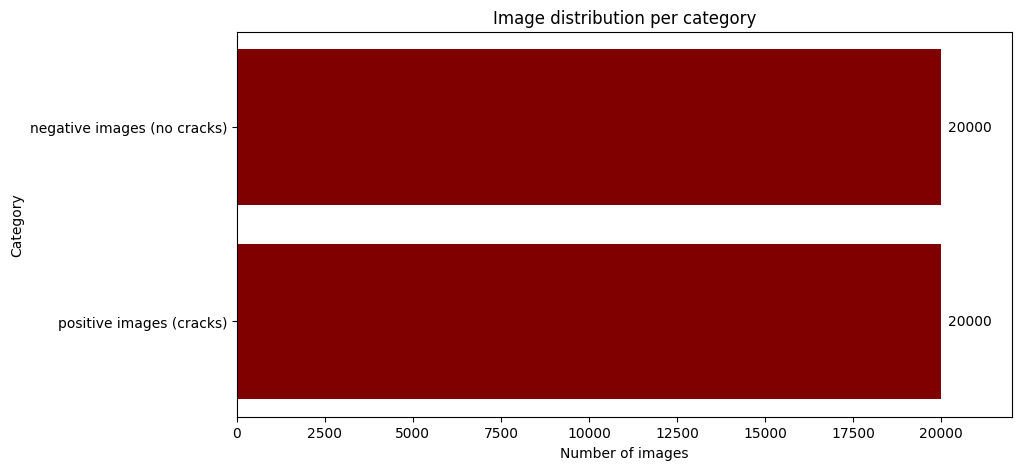

In [30]:
# https://www.geeksforgeeks.org/python/matplotlib-pyplot-barh-function-in-python/
positive_images = len(os.listdir(path / "Positive"))
negative_images = len(os.listdir(path / "Negative"))
data_nums = {'positive images (cracks)': positive_images, 'negative images (no cracks)': negative_images} # creating a dataset for our graph

courses = list(data_nums.keys()) # category
values = list(data_nums.values()) # count

fig = plt.figure(figsize=(10, 5)) 

# creating the bar plot
bars = plt.barh(courses, values, color='maroon') # horizontal bar chart
plt.bar_label(bars, padding=5, fmt='%d') # displaying the count beside each bar

plt.xlabel("Number of images")
plt.ylabel("Category")
plt.title("Image distribution per category")
plt.xlim(0, max(values) * 1.1) # preventing the counts from being clipped out .. xlim sets the limit of values in the x axis
plt.show()


## Examining pixel distributions

In [31]:
### AI USAGE REPORT

#https://www.geeksforgeeks.org/python/plotting-multiple-bar-charts-using-matplotlib-in-python/
# https://www.geeksforgeeks.org/python/how-to-calculate-the-mode-of-numpy-array/
"""
Prompt:
Create a function that summarises the mean pixel distribution for each directory

Result
the for loops shown below
"""

'\nPrompt:\nCreate a function that summarises the mean pixel distribution for each directory\n\nResult\nthe for loops shown below\n'

Negative mode: 189
positive mode: 180
Dark pixels: 0.28%
Positive dark pixels: 7.59%


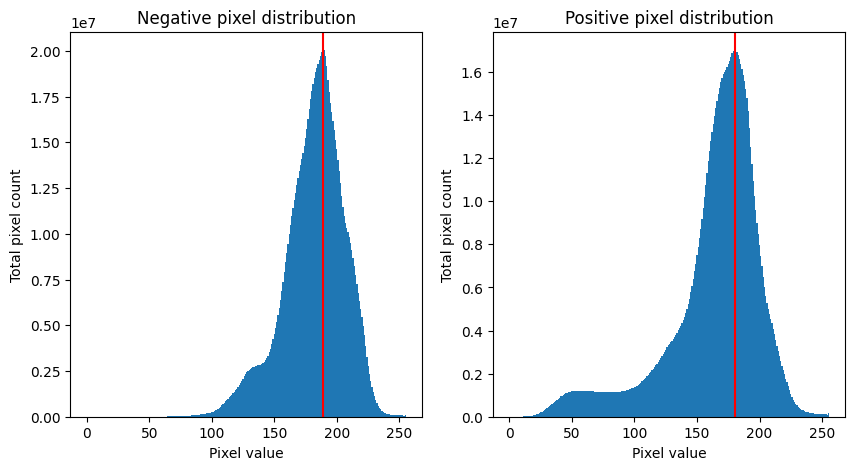

In [32]:
files_neg = os.listdir(path / "Negative")
hist_total_neg = np.zeros(256, dtype=np.int64) # creating an array of 256 0's 
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for fname in files_neg:
    img = cv2.imread(str(path / "Negative" / fname), cv2.IMREAD_GRAYSCALE) # reading our negative image
    hist_total_neg += np.bincount(img.ravel(), minlength=256)  # convert to bin counts and then sum to hist total

files_pos = os.listdir(path / "Positive")
hist_total_pos = np.zeros(256, dtype=np.int64) # creating an array of 256 0's 

for fname in files_pos:
    img = cv2.imread(str(path / "Positive" / fname), cv2.IMREAD_GRAYSCALE) # reading our positive image
    hist_total_pos += np.bincount(img.ravel(), minlength=256) # convert to bin counts and then sum to hist total


neg_mode = hist_total_neg.argmax() # mode
print(f"Negative mode: {neg_mode}")

axes[0].bar(range(256), hist_total_neg, width=1.0)

axes[0].set_xlabel("Pixel value")
axes[0].set_ylabel("Total pixel count")
axes[0].set_title("Negative pixel distribution")
axes[0].axvline(neg_mode,color="red", label="Mode") # using .axvline to draw a vertical line indicating the mode 


pos_mode = hist_total_pos.argmax() # mode (most common value)

print(f"positive mode: {pos_mode}")

axes[1].bar(range(256), hist_total_pos, width=1.0)

axes[1].set_xlabel("Pixel value")
axes[1].set_ylabel("Total pixel count")
axes[1].set_title("Positive pixel distribution")
axes[1].axvline(pos_mode,color="red", label="Mode")# using .axvline to draw a vertical line indicating the mode 

### pixel values less than 100
dark_percentage = hist_total_neg[:100].sum() / hist_total_neg.sum() * 100
print(f"Dark pixels: {dark_percentage:.2f}%")

dark_percentage_pos = hist_total_pos[:100].sum() / hist_total_pos.sum() * 100
print(f"Positive dark pixels: {dark_percentage_pos:.2f}%")


plt.show()

In [33]:
print(f'Positive length = {len(os.listdir(path / "Positive"))}')
print(f'Negative length = {len(os.listdir(path / "Negative"))}')

Positive length = 20000
Negative length = 20000


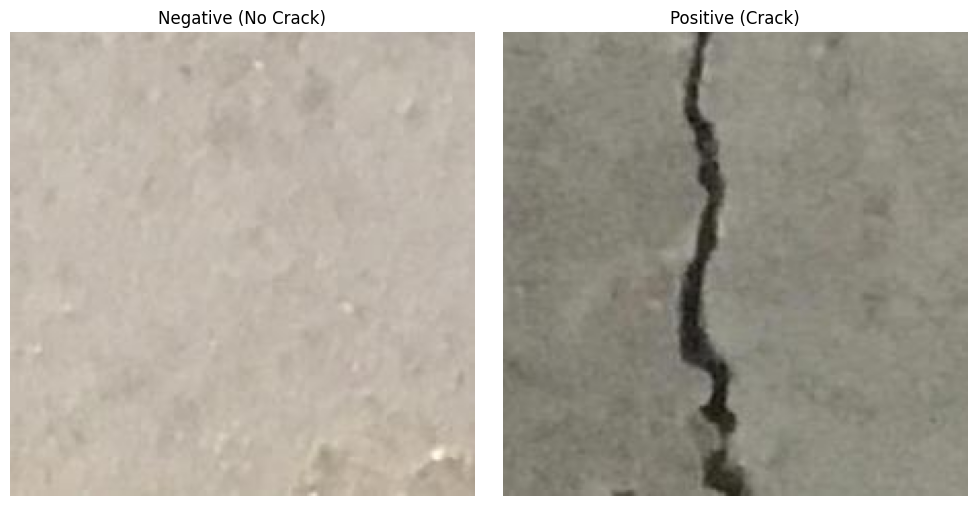

In [34]:
positive_img_example = "00091.jpg"
negative_img_example = "00614.jpg"
img = mpimg.imread(os.path.join(path / 'Negative', negative_img_example))
img2 = mpimg.imread(os.path.join(path / 'Positive', positive_img_example)) # reading the image

fig, axes = plt.subplots(1, 2, figsize=(10, 5)) # 1 row, 2 column plot

axes[0].imshow(img) # showing the image
axes[0].set_title('Negative (No Crack)')
axes[0].axis('off')

axes[1].imshow(img2)
axes[1].set_title('Positive (Crack)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Trialing a grayscale filter


Sources
* https://docs.opencv.org/3.1.0/dd/d49/tutorial_py_contour_features.html  - bounding rectangle
* https://www.geeksforgeeks.org/python/image-thresholding-in-python-opencv/ - binary thresholding
* https://docs.opencv.org/3.4.20/da/d0c/tutorial_bounding_rects_circles.html - canny output
* https://github.com/jupyter/notebook/issues/3935 - cv2_imshow()
* https://docs.opencv.org/3.4.20/d7/d4d/tutorial_py_thresholding.html - cv2.Blur
* https://stackoverflow.com/questions/41586429/opencv-saving-images-to-a-particular-folder-of-choice - cv2.imwrite
* https://docs.opencv.org/4.13.0/dd/d49/tutorial_py_contour_features.html - cv2.contourArea
* https://stackoverflow.com/questions/701402/best-way-to-choose-a-random-file-from-a-directory - random



# Creating the Masks

In [35]:
os.makedirs("Output_dir_cv2", exist_ok=True)
dir_path = path / 'Positive'
mask_zip_path = "/content/Output_dir_cv2.zip"
label_zip_path = "/content/Output_dir_labels_cv2.zip"

# Flag to track if we successfully extracted the cached masks
extracted_successfully = False

if os.path.exists(mask_zip_path) and os.path.exists(label_zip_path): # used to save time and not have to rerun code
    try:
        print("Attempting to extract zipped mask file...")
        with zipfile.ZipFile(mask_zip_path, 'r') as zip_ref:
            zip_ref.extractall("Output_dir_cv2") # extract the contents of the zip file to the specified directory
            os.remove(mask_zip_path) # remove the zip file after extraction to save space
        extracted_successfully = True
        print("Successfully extracted cached masks!")
    except zipfile.BadZipFile:
        print("Warning: The zip file was corrupted or invalid. Cleaning up and falling back to processing raw images.")
        if os.path.exists(mask_zip_path):
            os.remove(mask_zip_path)

# Fallback if no valid cached ZIP files are present
if not extracted_successfully:
    dir_path = path / 'Positive'

    contour_data = []
    for file in os.listdir(dir_path):
        img = cv2.imread(os.path.join(dir_path, file)) # read in our image
        img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) # convert to grayscale
        img_blurred = cv2.bilateralFilter(img_gray, 9, 75, 75) # use a proper filter
        
        threshold, binary = cv2.threshold(
            img_blurred, 0, 255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        ) # binary inversion so that cracks are white now, otsu for an adaptive treshold
        
        contours, hierarchy = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE) # find contours in the binary image
        valid_contours = [c for c in contours if len(c) >= 3 and cv2.contourArea(c) >= 20] # if we have a contour with less than 3 points, it is not a valid contour, and if the area is less than 20 pixels, it is likely noise
        contour_img = img.copy() # create a copy of the original image to draw contours on
        
        cv2.drawContours(contour_img, valid_contours, -1, (0, 255, 0), 2) # draw the contours on the image
        contour_data.append([file, valid_contours]) # record the filename and its corresponding valid contours for later use

        cv2.imwrite(f'Output_dir_cv2/{file}', contour_img) # save the image with contours drawn on it


In [36]:
print(f"Masks  = {len(os.listdir('Output_dir_cv2'))}") # Printing the number of masks generated and saved in the Output_dir_cv2 directory


Masks  = 20000


# Create YOLO annotations
https://docs.ultralytics.com/usage/simple-utilities

In [37]:
"""
[
    [[178, 70]],
    [[177, 71]],
    [[177, 72]],
    ...
]

becomes
[
    [178, 70],
    [177, 71],
    [177, 72],
    ...
]
"""
label_zip_path = "/content/Output_dir_labels_cv2.zip"


os.makedirs("./content/rejected_images",exist_ok=True) #creating a directory to store rejected images
os.makedirs("./content/crack_dataset/label_files", exist_ok=True) #creating a directory to store label files
if os.path.exists(label_zip_path):
    with zipfile.ZipFile(label_zip_path, 'r') as zip_ref:
        zip_ref.extractall("labels_cv2")
        os.remove(label_zip_path)
else:
    h, w = img.shape[:2]
    for file, contours in contour_data:
        yolo_lines = []
        for contour in contours:
            # Convert [[x,y]] -> [x,y]
            points = contour.reshape(-1, 2) # Take all these contour coordinates and organize them into rows of [x, y]

            # Normalize coordinates for YOLO
            points = points.astype(float)
            points[:, 0] /= w # normalising using width
            points[:, 1] /= h # normalising using height

            # YOLO format: class x1 y1 x2 y2 ...
            line = "0 " + " ".join(
                f"{x:.6f} {y:.6f}" for x, y in points
            ) # Limit to 6 decimal places
            yolo_lines.append(line)

        if yolo_lines:
            with open(f"./content/crack_dataset/label_files/{file[:-4]}_positive.txt", "w") as f:
                f.write("\n".join(yolo_lines)) # write the lines to the file
        else:
            img = cv2.imread(os.path.join(dir_path, file)) # read in our image
            rej_img = cv2.imread(os.path.join(dir_path, file)) # read in our image
            if rej_img is not None:
                cv2.imwrite(os.path.join('./content/rejected_images', file), rej_img)# save the rejected image to the rejected_images directory
                os.remove(os.path.join(dir_path, file)) # remove the rejected image from the original directory
            else:
                print(f"could not read {file} for rejection")

In [38]:
len(os.listdir('./content/crack_dataset/label_files'))

20000

In [39]:
def write_single_label(image,filename,path):
    img_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) # convert to grayscale
    img_blurred = cv2.bilateralFilter(img_gray, 9, 75, 75) # use a proper filter
    
    threshold, binary = cv2.threshold(
        img_blurred, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    ) # binary inversion so that cracks are white now, otsu for an adaptive treshold
    
    contours, hierarchy = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE) #find the contours in the binary image
    valid_contours = [c for c in contours if len(c) >= 3 and cv2.contourArea(c) >= 20]  # if we have a contour with less than 3 points, it is not a valid contour, and if the area is less than 20 pixels, it is likely noise
    h, w = image.shape[:2]
    yolo_lines = []
    for contour in valid_contours:
        # Convert [[x,y]] -> [x,y]
        points = contour.reshape(-1, 2) # Take all these contour coordinates and organize them into rows of [x, y]

        # Normalize coordinates for YOLO
        points = points.astype(float)
        points[:, 0] /= w
        points[:, 1] /= h

        # YOLO format: class x1 y1 x2 y2 ...
        line = "0 " + " ".join(
            f"{x:.6f} {y:.6f}" for x, y in points
        ) # Limit to 6 decimal places
        yolo_lines.append(line)

    if yolo_lines:
        with open(f"{path}/{filename}.txt", "w") as f:
            f.write("\n".join(yolo_lines))
    return bool(yolo_lines)

# Refactor names and lump into dataset


In [40]:
print(os.listdir('./content/surface-crack-detection/Positive/')[:5])
print(os.listdir('./content/surface-crack-detection/Negative/')[:5]) # printing the first 5 images in the negative directory to verify that they are there

['00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg']
['00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg']


In [41]:
positive_path = "./content/surface-crack-detection/Positive/"
negative_path = "./content/surface-crack-detection/Negative/"
label_path = "./content/crack_dataset/label_files/"
for fileName in os.listdir(positive_path):
    os.rename(positive_path + fileName, positive_path + f'{fileName[:-4]}_positive.jpg') # renaming the positive images to have a suffix of "_positive.jpg" for clarity and consistency

for fileName in os.listdir(negative_path):
    os.rename(negative_path + fileName, negative_path +  f'{fileName[:-4]}_negative.jpg') # renaming the negative images to have a suffix of "_negative.jpg" for clarity and consistency

In [42]:
print(os.listdir('./content/surface-crack-detection/Positive/')[-1])
print(os.listdir('./content/surface-crack-detection/Negative/')[-1])

20000_positive.jpg
20000_negative.jpg


# Creating a correctly formatted directory


# Splitting our data
https://pypi.org/project/split-folders/


In [43]:
splitfolders.ratio("./content/surface-crack-detection", output="./content/crack_dataset/splits", seed=1337, ratio=(.8, .1, .1)) # Splitting our data

"""
We should freeze this to evaluate other models against our baseline on the same splits for fairness
"""

Copying files: 40000 files [04:33, 146.48 files/s]


'\nWe should freeze this to evaluate other models against our baseline on the same splits for fairness\n'

In [44]:
print(len(os.listdir('content/crack_dataset/splits/train/Negative')))

16000


## Formatting dir structure to suit ultralytics yolo format

In [45]:
shutil.copytree('./content/crack_dataset/splits/test/Negative', './content/crack_dataset/splits/test',dirs_exist_ok=True) #put it into test
shutil.rmtree('./content/crack_dataset/splits/test/Negative') # delete the old dir
shutil.copytree('./content/crack_dataset/splits/test/Positive', './content/crack_dataset/splits/test',dirs_exist_ok=True)
shutil.rmtree('./content/crack_dataset/splits/test/Positive') # delete the old dir

In [46]:
shutil.copytree('./content/crack_dataset/splits/train/Negative', './content/crack_dataset/splits/train',dirs_exist_ok=True) #put it into train
shutil.rmtree('./content/crack_dataset/splits/train/Negative') # delete the old dir
shutil.copytree('./content/crack_dataset/splits/train/Positive', './content/crack_dataset/splits/train',dirs_exist_ok=True)
shutil.rmtree('./content/crack_dataset/splits/train/Positive')

In [47]:
shutil.copytree('./content/crack_dataset/splits/val/Negative', './content/crack_dataset/splits/val',dirs_exist_ok=True) #put it into val
shutil.rmtree('./content/crack_dataset/splits/val/Negative') # delete the old dir
shutil.copytree('./content/crack_dataset/splits/val/Positive', './content/crack_dataset/splits/val',dirs_exist_ok=True)
shutil.rmtree('./content/crack_dataset/splits/val/Positive')

In [48]:

dir_val = './content/crack_dataset/splits/val'
dir_train = './content/crack_dataset/splits/train'
dir_test = './content/crack_dataset/splits/test'
label_dir = './content/crack_dataset/label_files'


for file in os.listdir(dir_val):
    img = cv2.imread(f'{dir_val}/{file}')
    if img is None:
        print(f"Failed to load: {file}")
        continue
    for i in range(1,4):
        if i == 1:
            transformed_img = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE) # rotate 90 degrees
        elif i == 2:
            transformed_img = cv2.rotate(img, cv2.ROTATE_180) # rotate 180 degrees
        else:
            transformed_img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE) # rotate 270 degrees

        #[:-4]_positive.txt
        out_name = f"{file[:-4]}_{i}" # create a new name for the transformed image
        cv2.imwrite(f'{dir_val}/{out_name}.jpg', transformed_img) # save the transformed image
        if file[-12:-4] == "positive": # if the file is a positive image, we need to write the label for it
            if not write_single_label(transformed_img, out_name, label_dir):
                os.remove(f'{dir_val}/{out_name}.jpg') # remove the image if we failed to write the label for it

for file in os.listdir(dir_train):
    img = cv2.imread(f'{dir_train}/{file}')
    if img is None:
        print(f"Failed to load: {file}")
        continue
    for i in range(1,4):
        if i == 1:
            transformed_img = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE) # rotate 90
        elif i == 2:
            transformed_img = cv2.rotate(img, cv2.ROTATE_180) # rotate 180
        else:
            transformed_img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE) # rotate 270

        out_name = f"{file[:-4]}_{i}" # create a new name for the transformed image
        cv2.imwrite(f'{dir_train}/{out_name}.jpg', transformed_img) # save the transformed image
        if file[-12:-4] == "positive": # if the file is a positive image, we need to write the label for it
            if not write_single_label(transformed_img, out_name, label_dir):
                os.remove(f'{dir_train}/{out_name}.jpg') # remove the image if we failed to write the label for it

for file in os.listdir(dir_test):
    img = cv2.imread(f'{dir_test}/{file}')
    if img is None:
        print(f"Failed to load: {file}")
        continue
    for i in range(1,4):
        if i == 1:
            transformed_img = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE) # rotate 90
        elif i == 2:
            transformed_img = cv2.rotate(img, cv2.ROTATE_180) #rotate 180
        else:
            transformed_img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE) #rotate 270

        out_name = f"{file[:-4]}_{i}" # create a new name for the transformed image
        cv2.imwrite(f'{dir_test}/{out_name}.jpg', transformed_img) # save the transformed image
        if file[-12:-4] == "positive": # if the file is a positive image, we need to write the label for it
            if not write_single_label(transformed_img, out_name, label_dir):
                os.remove(f'{dir_test}/{out_name}.jpg') # remove the image if we failed to write the label for it


Failed to load: .complete
Failed to load: .complete
Failed to load: .complete


# Now we need to put our labels in splits and sort it according to train/val/test to correspond with positives

In [49]:
print(os.listdir('content/crack_dataset/label_files')[:5])

['00001_positive.txt', '00001_positive_1.txt', '00001_positive_2.txt', '00001_positive_3.txt', '00002_positive.txt']


In [50]:
os.makedirs('./content/crack_dataset/splits/images', exist_ok=True)
shutil.move('./content/crack_dataset/splits/test', './content/crack_dataset/splits/images')
shutil.move('./content/crack_dataset/splits/train', './content/crack_dataset/splits/images')# moving the train and test directories into a new directory called images for clarity
shutil.move('./content/crack_dataset/splits/val', './content/crack_dataset/splits/images')

'./content/crack_dataset/splits/images\\val'

In [51]:
print(os.listdir('content/crack_dataset/splits/images/test')[:5])

['.complete', '00004_negative.jpg', '00004_negative_1.jpg', '00004_negative_2.jpg', '00004_negative_3.jpg']


## AI usage summary

### Prompt: how can I modify this code to run quicker

### Response: Suggested using sets and os.scandir for faster name comparison

In [52]:
label_dir = './content/crack_dataset/label_files'
splits_dir = './content/crack_dataset/splits'

# Create output label directories
train_label_dir = os.path.join(splits_dir, 'labels/train')
val_label_dir = os.path.join(splits_dir, 'labels/val')
test_label_dir = os.path.join(splits_dir, 'labels/test')

os.makedirs(train_label_dir, exist_ok=True)
os.makedirs(val_label_dir, exist_ok=True)
os.makedirs(test_label_dir, exist_ok=True)

# Pre-fetch image filenames into SETS for O(1) instant lookups
train_images = set(os.listdir(os.path.join(splits_dir, 'images/train'))) # create a set of all the image filenames in the training directory for fast lookup
val_images = set(os.listdir(os.path.join(splits_dir, 'images/val')))
test_images = set(os.listdir(os.path.join(splits_dir, 'images/test')))

# Use os.scandir for faster scanning of the label directory
with os.scandir(label_dir) as entries: # scan the label directory
    for entry in entries: # iterate through each entry in the directory
        if entry.is_file() and entry.name.endswith('.txt'): # check if the entry is a file and ends with .txt
            label_file = entry.name # get the name of the label file
            image_name = f"{os.path.splitext(label_file)[0]}.jpg" # get the corresponding image name by replacing the .txt extension with .jpg
            src_path = entry.path # get the full path to the label file

            if image_name in train_images: # if the image is in the training set
                shutil.copy(src_path, train_label_dir) # copy the label file to the training label directory
            elif image_name in val_images:
                shutil.copy(src_path, val_label_dir) # copy the label file to the validation label directory
            elif image_name in test_images:
                shutil.copy(src_path, test_label_dir) # copy the label file to the test label directory
            else:
                print(f'{image_name} not found in dataset')

# Making the YAML for our yolo model

In [53]:
for split in ["train", "val", "test"]:
    n_labels = len(os.listdir(f"content/crack_dataset/splits/labels/{split}"))
    print(f"{split}: {n_labels} label files") # print out the number of files in each dir

train: 64000 label files
val: 8000 label files
test: 8000 label files


In [54]:
len(os.listdir('content/crack_dataset/splits/labels/train'))

64000

In [55]:
# per ultralytics documentation, we need to create a yaml file for our dataset
yaml_text = """ 
path: ./content/crack_dataset/splits
train: images/train
val: images/val
test: images/test

names:
  0: crack
"""
with open('./content/crack_dataset/crack.yaml', 'w') as f:
    f.write(yaml_text)# writing the yaml text

# Training model
This works, but I keyboard interrupt because it takes ages to train.

In [ ]:
model = YOLO("yolo26n-seg.pt") # yolo26n-seg.pt model
model.train(data="./content/crack_dataset/crack.yaml", epochs=100, imgsz=256) # training the model for 100 epochs with an image size of 256x256
# optimiser is muSGD by default, but it can be changed using 'optimizer' parameter

New https://pypi.org/project/ultralytics/8.4.198 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.194  Python-3.10.0 torch-2.10.0+cpu CPU (AMD Ryzen 7 7730U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./content/crack_dataset/crack.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo

KeyboardInterrupt: 

In [58]:
metrics = model.val(
    data="./content/crack_dataset/crack.yaml",
    split="test",
    plots=True
) # evaluating the model on the test set 

Ultralytics 8.4.194  Python-3.10.0 torch-2.10.0+cpu CPU (AMD Ryzen 7 7730U with Radeon Graphics)
YOLO26n-seg summary (fused): 137 layers, 2,703,783 parameters, 20,063 gradients, 9.1 GFLOPs
val: Fast image access  (ping: 0.2±0.0 ms, read: 3.3±3.1 MB/s, size: 8.0 KB)
val: Scanning C:\Users\downe\Downloads\content\crack_dataset\splits\labels\test... 8000 images, 8000 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 16000/16000 519.7it/s 30.8s0.0ss
val: New cache created: C:\Users\downe\Downloads\content\crack_dataset\splits\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1000/1000 2.0s/it 32:56.4ss
                   all      16000      20476    0.00234      0.548      0.014    0.00485    0.00212      0.496    0.00651    0.00191
Speed: 1.7ms preprocess, 76.5ms inference, 0.0ms loss, 30.1ms postprocess per image
Results saved to C:\Users\downe\Downloads\runs\segment\val


In [59]:
print(metrics.results_dict) # printing the results of the evaluation

{'metrics/precision(B)': 0.0023375, 'metrics/recall(B)': 0.547958585661262, 'metrics/mAP50(B)': 0.013961627376691918, 'metrics/mAP50-95(B)': 0.004849901081811104, 'metrics/precision(M)': 0.002116875, 'metrics/recall(M)': 0.4962394999023247, 'metrics/mAP50(M)': 0.006507367764259374, 'metrics/mAP50-95(M)': 0.0019099277444917348, 'fitness': 0.006759828826302839}


In [60]:
directory = "runs/segment"
# https://stackoverflow.com/questions/2014554/find-the-newest-folder-in-a-directory-in-python
train_name = max([os.path.join(directory,d) for d in os.listdir(directory) if d.startswith("train")], key=os.path.getmtime).split(os.sep)[-1]
print(train_name)

train


File: 09479_positive.jpg | IoU: 0.8750


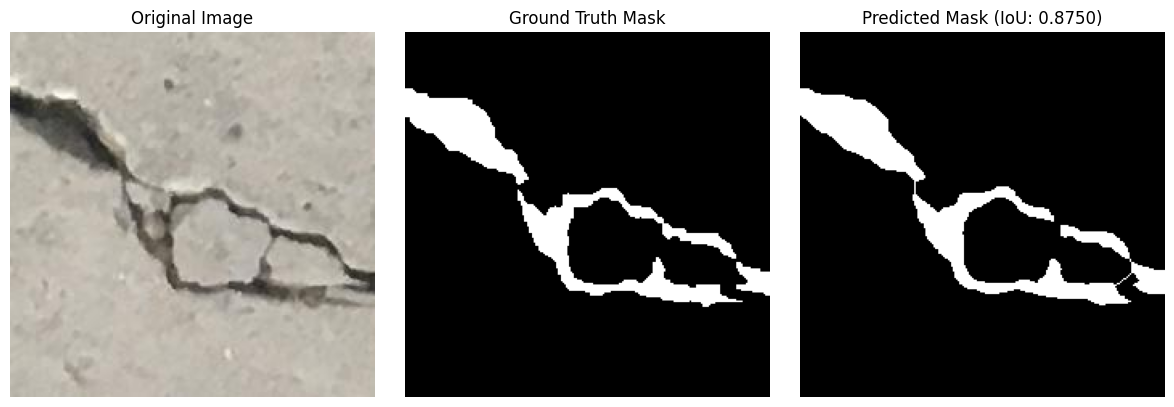

File: 12061_1_positive_3.jpg | IoU: 0.8992


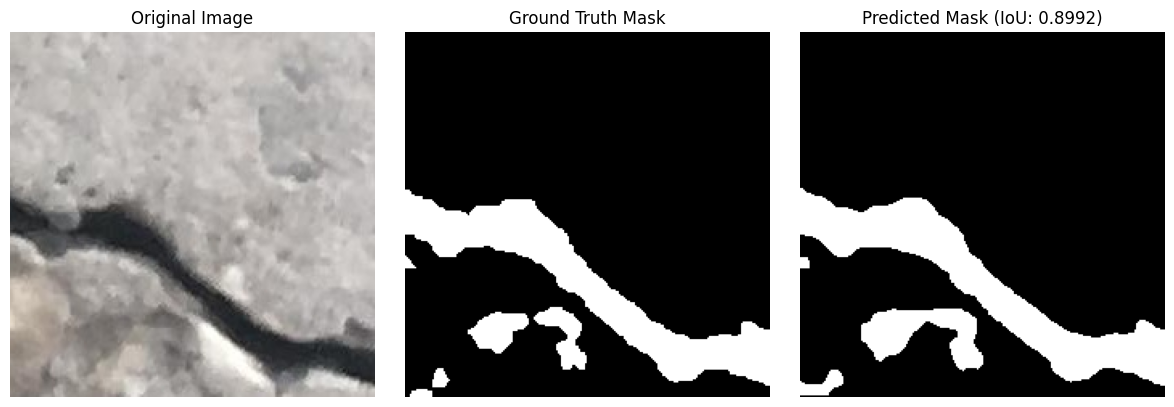

File: 18033_1_positive_3.jpg | IoU: 0.9254


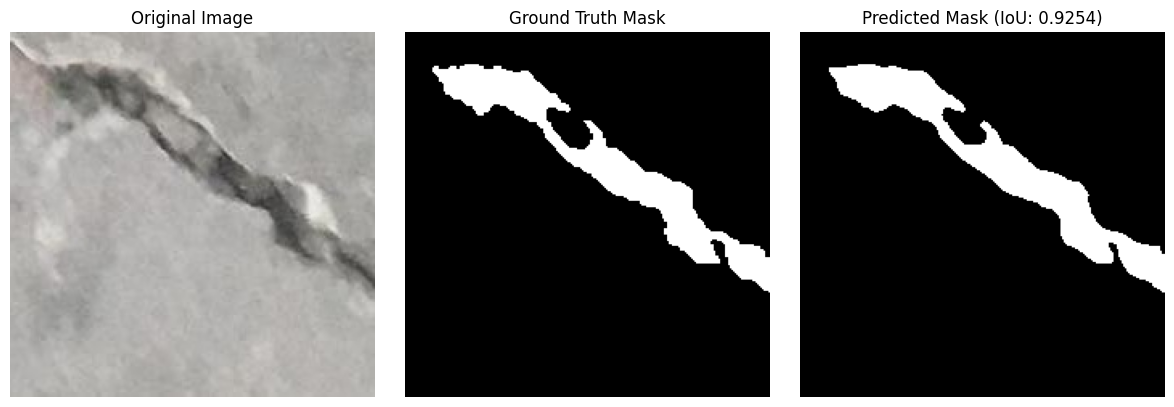

File: 10780_1_positive.jpg | IoU: 0.8983


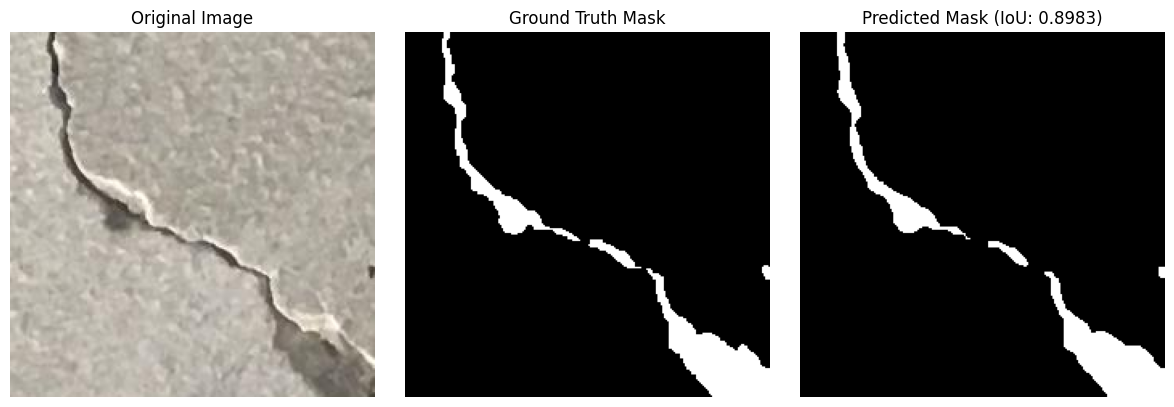

File: 00833_positive.jpg | IoU: 0.9178


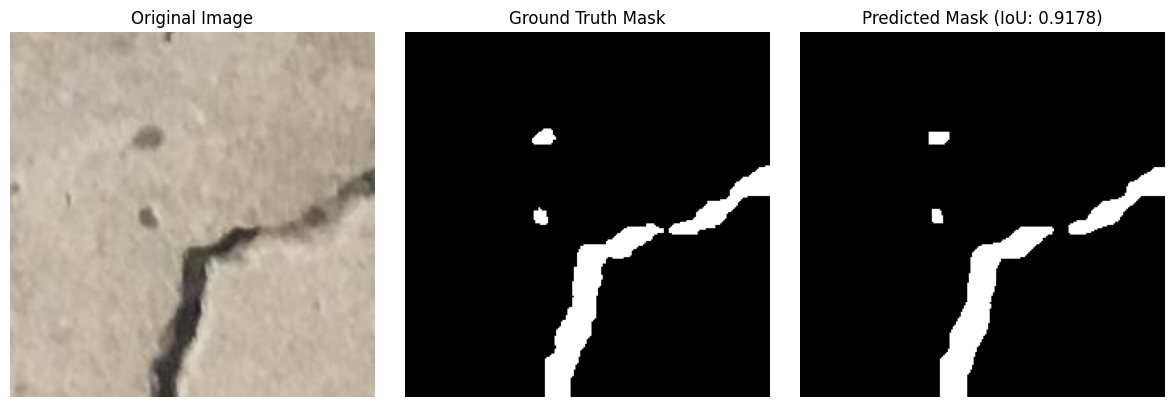

In [61]:
# 1. Define directories
IMG_DIR = "content/crack_dataset/splits/images/val"
LBL_DIR = "content/crack_dataset/splits/labels/val"
OUT_DIR = "IoU"
os.makedirs(OUT_DIR, exist_ok=True)

# 2. Calculate IoU
def mask_iou(mask1: torch.Tensor, mask2: torch.Tensor, eps: float = 1e-7) -> torch.Tensor: # calculating the intersection over union (IoU) between two masks
    intersection = torch.matmul(mask1, mask2.T).clamp_(0) # using matrix multiplication to calculate the intersection of the two masks
    union = (mask1.sum(1)[:, None] + mask2.sum(1)[None]) - intersection # union is the sum of the two masks minus the intersection
    return intersection / (union + eps) # adding a small epsilon to prevent division by zero

# 3. Create ground-truth mask from label file
def gt_mask(txt_path, h, w): # creating a ground-truth mask from a YOLO label file
    mask = np.zeros((h, w), dtype=np.uint8) # creating a blank mask of the same size as the image

    if not os.path.exists(txt_path): # if the label file does not exist, return the blank mask
        return mask # return the blank mask

    with open(txt_path, "r") as f: # open the label file
        for line in f.readlines(): # iterate through each line in the label file
            parts = line.strip().split() # split the line into parts (class and coordinates)

            if len(parts) < 3: # if there are not enough parts in the line, skip this line
                continue 

            coords = np.array([float(x) for x in parts[1:]]).reshape(-1, 2) # reshape the coordinates into a 2D array of (x, y) pairs
            coords[:, 0] *= w # multiply the x-coordinates by the width of the image to get pixel coordinates
            coords[:, 1] *= h # multiply the y-coordinates by the height of the image to get pixel coordinates
            coords = coords.astype(np.int32) # convert the coordinates to integers

            cv2.fillPoly(mask, [coords], 1) # fill the polygon defined by the coordinates in the mask with a value of 1

    return mask

# 4. Create predicted mask from YOLO result
def pred_mask(result, h, w): # creating a predicted mask from the YOLO model's output
    mask = np.zeros((h, w), dtype=np.uint8) # creating a blank mask of the same size as the image

    if result.masks is not None: # if the model has predicted masks, we will fill in the predicted mask
        for m in result.masks.xy: # iterate through each predicted mask's coordinates
            if len(m) > 0: # if there are coordinates for this mask, we will fill in the predicted mask
                coords = m.astype(np.int32) # convert the coordinates to integers
                cv2.fillPoly(mask, [coords], 1) # fill the polygon defined by the coordinates in the mask with a value of 1

    return mask

# 5. Load trained model once (fallback to standard weights if best.pt is missing)
model_path = f"runs/segment/{train_name}/weights/best.pt" # path to the best model weights from the training run

if not os.path.exists(model_path):
    # If you haven't run/completed a full training run yet, we fallback to pretrained weights
    model_path = "yolo26n-seg.pt"
    print(f"Warning: Trained model not found at best.pt. Falling back to pretrained weights: {model_path}")

model = YOLO(model_path) # loading the YOLO model with the specified weights

# 6. Select validation images (look for positive first, fallback to any available images)

SEED = 40  # change this to get a different (but still reproducible) set of images

if os.path.exists(IMG_DIR): # check if the validation image directory exists
    rng = random.Random(SEED) # create a random number generator with the specified seed for reproducibility

    positive_files = sorted( 
        f for f in os.listdir(IMG_DIR)
        if f.endswith(".jpg") and "_positive" in f
    ) # get a sorted list of all positive validation images (those containing "_positive" in their filename)

    if positive_files:
        val_files = rng.sample(positive_files, min(5, len(positive_files))) # randomly select up to 5 positive validation images from the list
    else:
        print("No validation images containing '_positive' found due to small dataset split. Selecting any available images.")
        all_files = sorted(f for f in os.listdir(IMG_DIR) if f.endswith(".jpg")) # get a sorted list of all validation images (those ending with ".jpg")
        val_files = rng.sample(all_files, min(5, len(all_files))) # randomly select up to 5 validation images from the list of all available images
else:
    val_files = []

if not val_files:
    print(f"Error: Validation directory '{IMG_DIR}' is empty or does not exist.")
else:
    # 7. Process each image
    for f in val_files:
        img_path = os.path.join(IMG_DIR, f) # get the full path to the image file
        txt_path = os.path.join(LBL_DIR, f[:-4] + ".txt") # get the corresponding label file path by replacing the image extension with ".txt"

        img = cv2.imread(img_path) # read the image using OpenCV

        if img is None:
            print(f"Could not load image: {f}")
            continue

        h, w = img.shape[:2] # get the height and width of the image

        # Create ground-truth mask
        gt = gt_mask(txt_path, h, w)

        # Run YOLO prediction
        result = model.predict(img_path, imgsz=256, verbose=False)[0]

        # Create predicted mask
        pr = pred_mask(result, h, w)

        # Convert masks to PyTorch tensors
        gt_tensor = torch.from_numpy(gt).float().view(1, -1)
        pr_tensor = torch.from_numpy(pr).float().view(1, -1)

        # Calculate IoU
        iou = mask_iou(gt_tensor, pr_tensor).item()

        print(f"File: {f} | IoU: {iou:.4f}")

        # Display comparison
        fig, axes = plt.subplots(1, 3, figsize=(12, 4))

        axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)) # convert BGR to RGB for correct color display
        axes[0].set_title("Original Image")
        axes[0].axis("off")

        axes[1].imshow(gt, cmap="gray")
        axes[1].set_title("Ground Truth Mask")
        axes[1].axis("off")

        axes[2].imshow(pr, cmap="gray")
        axes[2].set_title(f"Predicted Mask (IoU: {iou:.4f})")
        axes[2].axis("off")

        plt.tight_layout()
         # Save the 3-panel figure as one PNG in the IoU folder
        save_path = os.path.join(OUT_DIR, f"{os.path.splitext(f)[0]}_iou.png")
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        plt.show()

In [62]:
def pred_mask_scores(result, h, w):
    scores = np.zeros((h, w), dtype=np.float32) # creating a blank score mask of the same size as the image

    # No masks predicted
    if result.masks is None or result.boxes is None:
        return scores

    masks = result.masks.data.cpu().numpy() # converting the predicted masks to a numpy array
    confidences = result.boxes.conf.cpu().numpy() # converting the predicted bounding box confidences to a numpy array

    # Combine instance masks using their detection confidence.
    for mask, confidence in zip(masks, confidences): 
        resized_mask = cv2.resize(
            mask.astype(np.float32),
            (w, h),
            interpolation=cv2.INTER_LINEAR
        ) # resizing the predicted mask to match the original image dimensions using linear interpolation

        # Keep the maximum confidence where masks overlap.
        scores = np.maximum(
            scores,
            resized_mask * float(confidence)
        )

    return np.clip(scores, 0.0, 1.0) # clipping the scores to ensure they are within the range [0.0, 1.0]

In [63]:
# Label mask
def label_mask(txt_path, h, w):
    mask = np.zeros((h, w), dtype=np.uint8) # creating a blank label mask of the same size as the image

    if not os.path.exists(txt_path):# if the label file does not exist, return the blank mask
        return mask # return the blank mask

    with open(txt_path, "r") as f:
        for line in f.readlines(): # iterate through each line in the label file
            parts = line.strip().split() # split the line into parts (class and coordinates)

            if len(parts) < 3:
                continue

            coords = np.array([float(x) for x in parts[1:]]).reshape(-1, 2) # reshape the coordinates into a 2D array of (x, y) pairs
            coords[:, 0] *= w # multiply the x-coordinates by the width of the image to get pixel coordinates
            coords[:, 1] *= h # multiply the y-coordinates by the height of the image to get pixel coordinates
            coords = coords.astype(np.int32) # convert the coordinates to integers

            cv2.fillPoly(mask, [coords], 1) # fill the polygon defined by the coordinates in the mask with a value of 1

    return mask

In [64]:
BASE_DIR = Path("runs/segment") # Base directory for segmentation results
TRAINS = [f"{train_name}"] # List of training runs to evaluate
DATA_YAML = 'content/crack_dataset/crack.yaml'

TEST_IMAGES = Path("./content/crack_dataset/splits/images/test")
TEST_LABELS = Path("./content/crack_dataset/splits/labels/test")

images = sorted(
    p for p in TEST_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"} # only include image files with these extensions
)

results = {}
map_results = {}

In [65]:
for train in TRAINS: # iterate through each training run
    print(f"\nEvaluating {train}")

    model = YOLO(str(BASE_DIR / train / "weights" / "best.pt")) # loading the YOLO model with the best weights from the specified training run

    positive_ious = []
    negative_false_positives = []
    all_ious = []

    for image_path in images:
        img = cv2.imread(str(image_path))

        if img is None:
            print(f"Could not load: {image_path}")
            continue

        h, w = img.shape[:2] # get the height and width of the image

        txt_path = TEST_LABELS / f"{image_path.stem}.txt" # get the corresponding label file path by replacing the image extension with ".txt"

        label = (label_mask(str(txt_path), h, w) > 0).astype(np.uint8) # create the ground-truth mask from the label file

        result = model.predict(
            source=img,
            imgsz=256,
            verbose=False
        )[0] # get the prediction result from the model for the given image

        pred = (pred_mask(result, h, w) > 0).astype(np.uint8) # create the predicted mask from the model's output

        # Ensure both masks have the same dimensions.
        assert label.shape == pred.shape == (h, w) 

        intersection = np.logical_and(label, pred).sum() # calculate the intersection of the ground-truth and predicted masks
        union = np.logical_or(label, pred).sum() # calculate the union of the ground-truth and predicted masks

        # Convention: IoU = 1 when both masks are empty.
        iou = intersection / union if union > 0 else 1.0
        all_ious.append(iou)

        if label.any():
            positive_ious.append(iou)
        else:
            # A negative image is a false positive if any crack
            # pixels are predicted.
            negative_false_positives.append(float(pred.any()))

    results[train] = {
        "mean_iou_all": np.mean(all_ious) if all_ious else np.nan,
        "mean_iou_positive": (
            np.mean(positive_ious) if positive_ious else np.nan
        ),
        "negative_false_positive_rate": (
            np.mean(negative_false_positives)
            if negative_false_positives else np.nan
        ),
        "n_images": len(all_ious),
        "n_positive": len(positive_ious),
        "n_negative": len(negative_false_positives),
    } # store the calculated metrics for the current training run in the results dictionary


Evaluating train


In [66]:
for train in TRAINS: # iterate through each training run again to evaluate mAP
    print(f"\nEvaluating mAP for {train}")

    model = YOLO(str(BASE_DIR / train / "weights" / "best.pt")) # loading the YOLO model with the best weights from the specified training run

    metrics = model.val(
        data=str(DATA_YAML),  # Your dataset YAML file
        split="test",
        imgsz=256,
        plots=False,
        verbose=False
    ) # evaluate the model on the test set to calculate mAP metrics

    # Segmentation metrics (not bounding-box metrics)
    map_results[train] = {
        "mAP50": metrics.seg.map50,
        "mAP50-95": metrics.seg.map,
    }

    print(f"mAP@50:    {metrics.seg.map50:.4f}") # print the mAP at IoU threshold 0.5
    print(f"mAP@50-95: {metrics.seg.map:.4f}") # print the mAP averaged over IoU thresholds from 0.5 to 0.95


Evaluating mAP for train
Ultralytics 8.4.194  Python-3.10.0 torch-2.10.0+cpu CPU (AMD Ryzen 7 7730U with Radeon Graphics)
YOLO26n-seg summary (fused): 137 layers, 2,703,783 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access  (ping: 0.2±0.1 ms, read: 44.0±18.2 MB/s, size: 11.7 KB)
val: Scanning C:\Users\downe\Downloads\content\crack_dataset\splits\labels\test.cache... 8000 images, 8000 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 16000/16000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1000/1000 2.7it/s 6:17.4ss
                   all      16000      20476      0.914      0.855      0.938      0.765      0.879      0.757      0.837       0.59
Speed: 0.3ms preprocess, 16.6ms inference, 0.0ms loss, 1.0ms postprocess per image
mAP@50:    0.8373
mAP@50-95: 0.5897


Selected 5 positive images


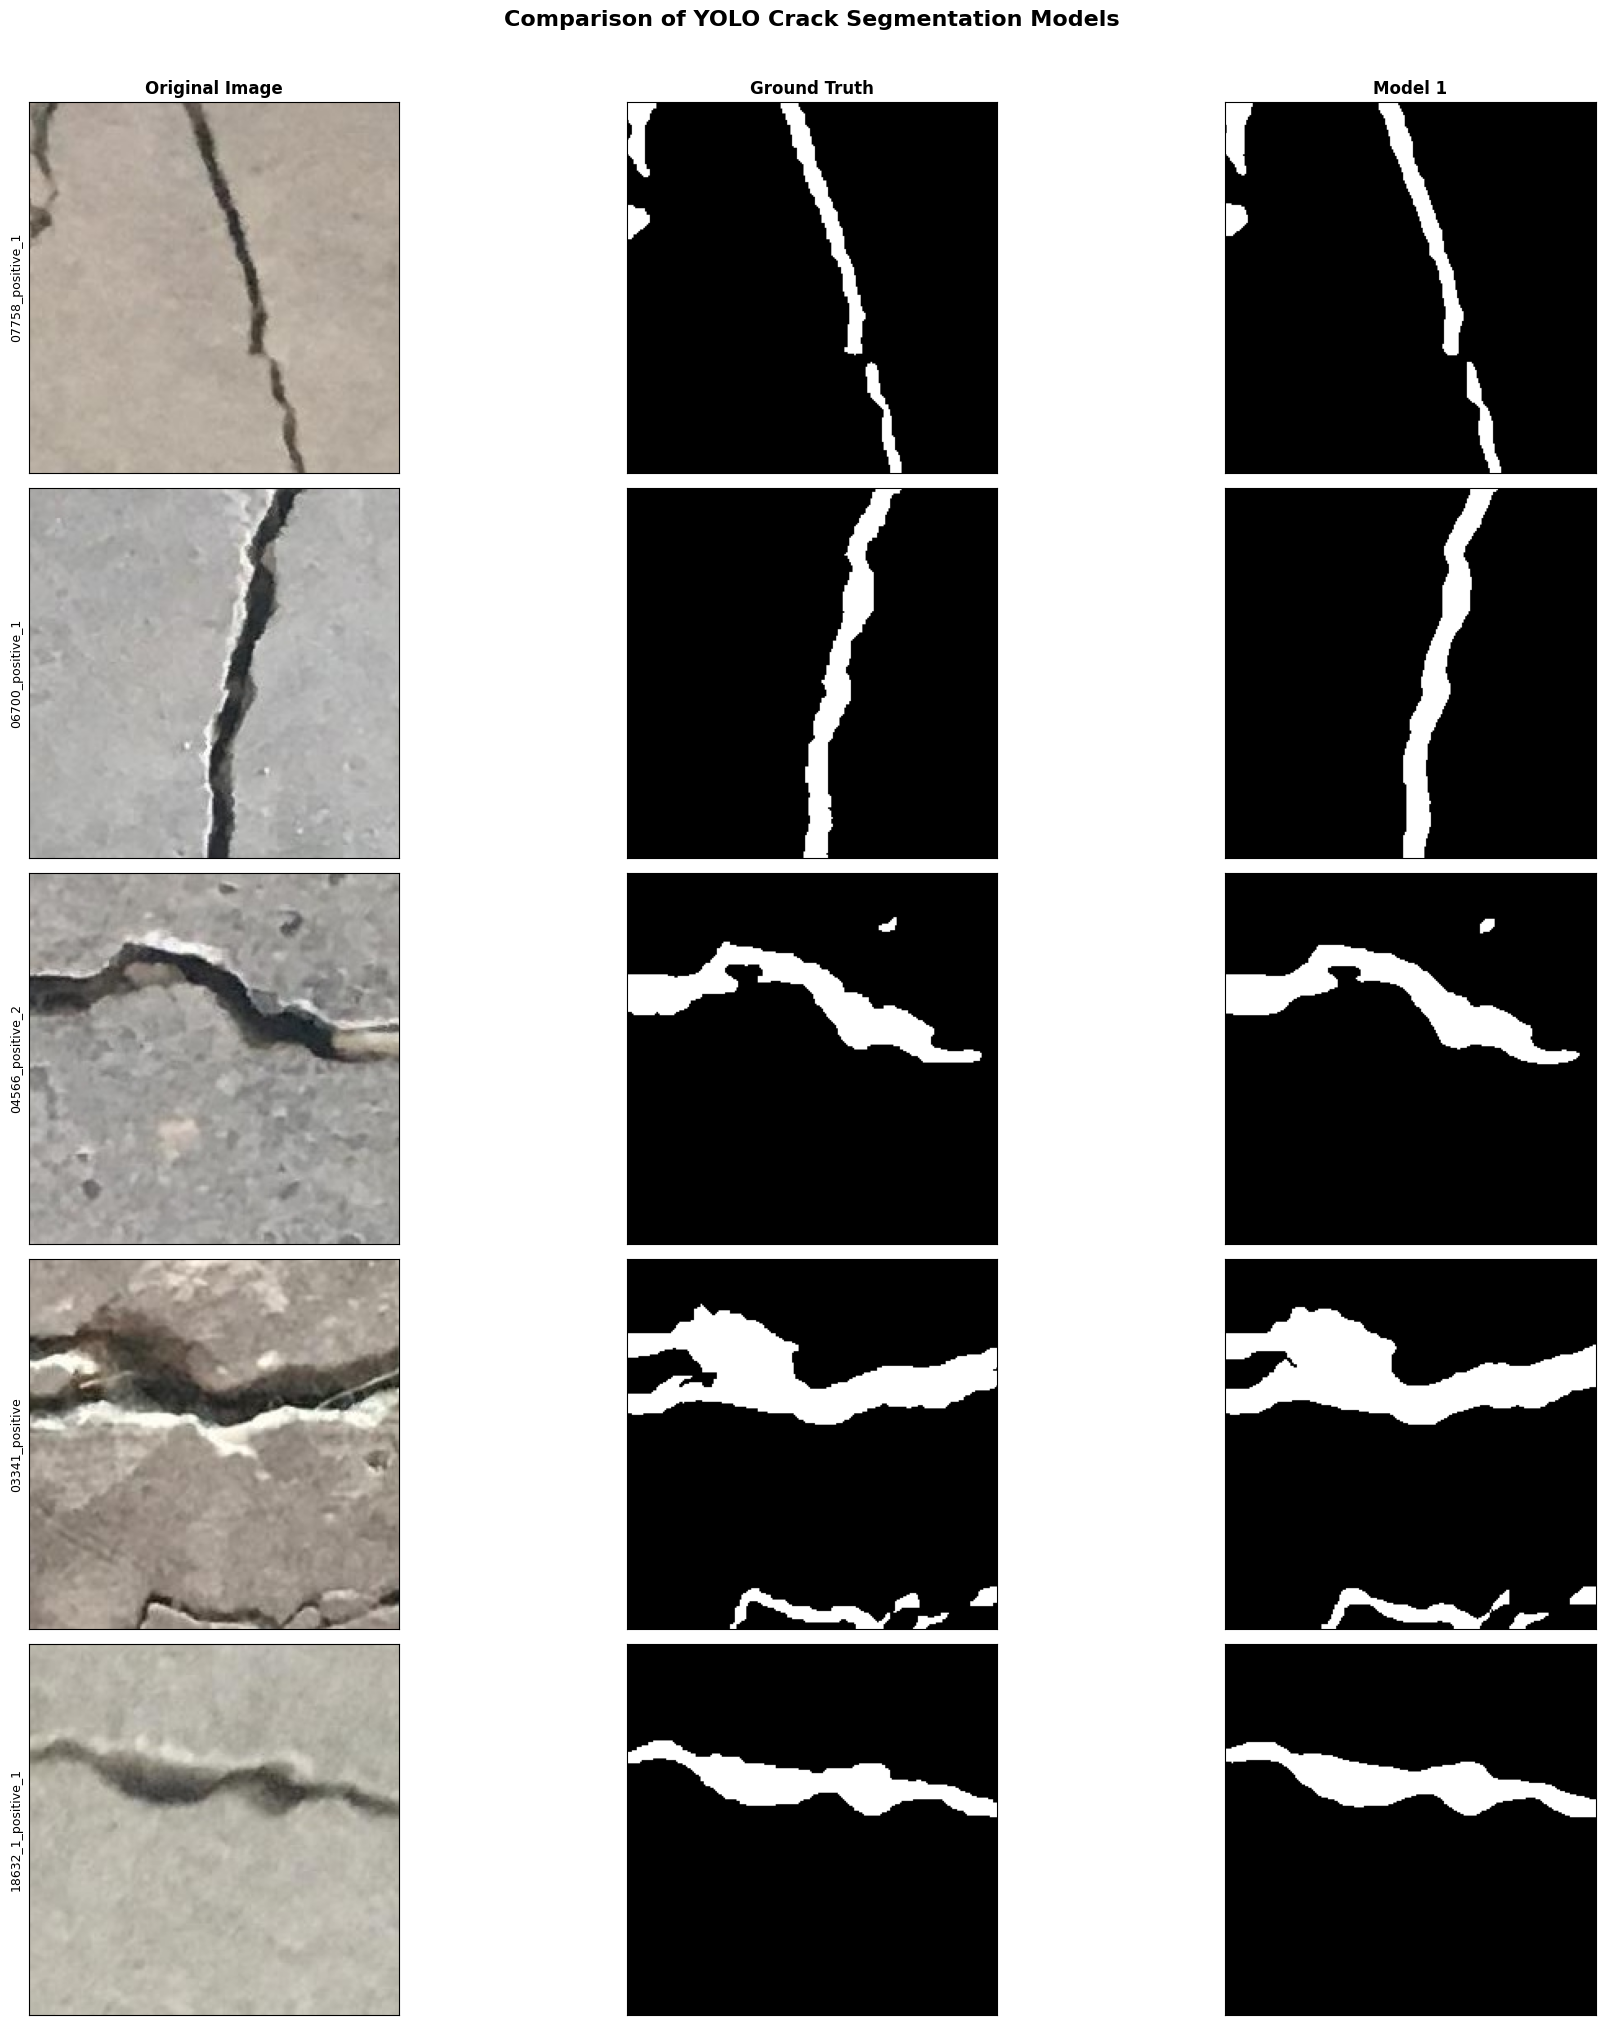

In [67]:
# Models to compare .... Train varying models and save their best.pt weights in the respective directories under runs/segment/
MODEL_DIRS = {
    "Model 1 ": BASE_DIR / TRAINS[0] / "weights" / "best.pt",
    #"Model 4 (Augmentation)": BASE_DIR / TRAINS[3] / "weights" / "best.pt",
    #"Model 5 (Otsu)": BASE_DIR / TRAINS[4] / "weights" / "best.pt",
}

# --------------------------------------------------
# 1. Select 5 positive images from the test dataset
# --------------------------------------------------

positive_images = []

for image_path in images: # iterate through each image in the test dataset
    img = cv2.imread(str(image_path))

    if img is None:
        continue

    h, w = img.shape[:2] # get the height and width of the image

    txt_path = TEST_LABELS / f"{image_path.stem}.txt" # get the corresponding label file path by replacing the image extension with ".txt"

    label = label_mask(str(txt_path), h, w) # create the ground-truth mask from the label file

    if np.any(label > 0): # if the ground-truth mask has any positive pixels (indicating the presence of a crack), we consider this image as a positive image
        positive_images.append(image_path)

# Randomly select 5 images
random.seed(41)

selected_images = random.sample(
    positive_images,
    min(5, len(positive_images))
) # randomly select up to 5 positive images from the list of positive images

print(f"Selected {len(selected_images)} positive images")


# --------------------------------------------------
# 2. Load the models
# --------------------------------------------------

models = {
    name: YOLO(str(path))
    for name, path in MODEL_DIRS.items()
} # load each model from the specified paths in MODEL_DIRS and store them in a dictionary with their names as keys


# --------------------------------------------------
# 3. Generate predictions and visualise
# --------------------------------------------------

fig, axes = plt.subplots(
    len(selected_images),
    3, ## CHANGE THIS IF YOU ADD MORE MODELS
    figsize=(20, 4 * len(selected_images))
) # create a matplotlib figure with subplots arranged in a grid, where the number of rows corresponds to the number of selected images and there are 5 columns for displaying the original image, ground truth, and predictions from each model

if len(selected_images) == 1:
    axes = np.expand_dims(axes, axis=0) # if there is only one selected image, expand the dimensions of the axes array to ensure it has a consistent shape for indexing

column_titles = [
    "Original Image",
    "Ground Truth",
    "Model 1"#,
    #"Model 4 (Augmentation)",
    #"Model 5 (Otsu)"
] # define the titles for each column in the visualization grid, corresponding to the original image, ground truth mask, and predictions from each model

for col, title in enumerate(column_titles):
    axes[0, col].set_title(title, fontsize=12, fontweight="bold") # set the title for each column in the first row of the axes grid, with specified font size and weight

for row, image_path in enumerate(selected_images):# iterate through each selected image and its corresponding row index in the visualization grid

    img = cv2.imread(str(image_path)) # read the image using OpenCV
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # convert the image from BGR to RGB color space for correct color display in matplotlib

    h, w = img.shape[:2] # get the height and width of the image

    # Ground truth
    txt_path = TEST_LABELS / f"{image_path.stem}.txt" # get the corresponding label file path by replacing the image extension with ".txt"

    label = (
        label_mask(str(txt_path), h, w) > 0
    ).astype(np.uint8) # create the ground-truth mask from the label file and convert it to a binary mask (0s and 1s) of type uint8

    # Original image
    axes[row, 0].imshow(img_rgb)
    axes[row, 0].set_ylabel(
        image_path.stem,
        fontsize=9
    ) # set the y-axis label for the current row in the visualization grid to the stem of the image filename (without extension), with specified font size

    # Ground truth mask
    axes[row, 1].imshow(label, cmap="gray", vmin=0, vmax=1) # display the ground-truth mask in the second column of the current row, using a grayscale colormap and setting the minimum and maximum values for display

    # Predictions from each model
    for col, (name, model) in enumerate(models.items(), start=2): # iterate through each model and its corresponding column index in the visualization grid, starting from column index 2 (after the original image and ground truth)

        result = model.predict(
            source=img,
            imgsz=256,
            verbose=False
        )[0] # get the prediction result from the model for the given image

        pred = (
            pred_mask(result, h, w) > 0
        ).astype(np.uint8) # create the predicted mask from the model's output and convert it to a binary mask (0s and 1s) of type uint8

        axes[row, col].imshow(
            pred,
            cmap="gray",
            vmin=0,
            vmax=1
        ) # display the predicted mask in the corresponding column of the current row, using a grayscale colormap and setting the minimum and maximum values for display

    # Remove axis ticks
    for col in range(3): # CHANGE THIS IF YOU ADD MORE MODELS
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

plt.suptitle(
    "Comparison of YOLO Crack Segmentation Models",
    fontsize=16,
    fontweight="bold",
    y=1.01
) # set the overall title for the entire figure, with specified font size, weight, and vertical position

plt.tight_layout() # adjust the layout of the subplots to minimize overlap and ensure a clean presentation
plt.show() # display the figure with the original images, ground truth masks, and predictions from each model

In [68]:
for train, metrics in results.items():
    print(f"\n{train}")
    for metric, value in metrics.items():
        print(f"  {metric}: {value:.4f}" if isinstance(value, (float, np.floating))
              else f"  {metric}: {value}")


train
  mean_iou_all: 0.9546
  mean_iou_positive: 0.9127
  negative_false_positive_rate: 0.0036
  n_images: 16000
  n_positive: 8000
  n_negative: 8000
